<a href="https://colab.research.google.com/github/Epot12/QML_project/blob/master/QML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#QML PROJECT

In [2]:
import os
import shutil
from google.colab import drive
import torch
import torch.nn as nn
import pandas as pd
import glob
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision.models import swin_b, Swin_B_Weights

drive.mount('/content/drive')

Mounted at /content/drive


##Exploratory Data Analysis INbreast

INbreast non si è rivelato l'alternativa migliore a causa di difficoltà nel preprocessing dei dati. Nello specifico, l'individuazione delle regioni tumorali tramite le coordinate ROI dà luogo a crop errati o poco informativi per il modello, a causa del formato complesso dei dati delle coordinate stesse, di cui è difficile fare il parsing.

In [ ]:
!pip install pydicom

In [ ]:
import pydicom

zip_path = '/content/drive/MyDrive/QML/INbreast/INbreast.zip'

# estrazione zip nella memoria temporanea di Colab, NON su Drive
# Questo percorso è veloce e si cancella alla chiusura di Colab
extract_path = '/content/data/INbreast_extracted'

print(f"File ZIP sorgente: {zip_path}")
print(f"Cartella di destinazione: {extract_path}")

# Estrazione (Unzip)
if not os.path.exists(extract_path):
    print("Estrazione in corso...")
    # Creo la cartella
    os.makedirs(extract_path, exist_ok=True)

    # Estraggo lo zip
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Estrazione completata!")
else:
    print("Dataset già estratto, procedo.")

# Ora cerco i DICOM nella cartella ESTRATTA (non nello zip)
dataset_root = extract_path  # punta alla cartella aperta!

print(f"Analisi del percorso: {dataset_root}")

dicom_files = []
for root, dirs, files in os.walk(dataset_root):
    for file in files:
        # AGGIUNTO: .roi e .m alla lista delle esclusioni
        if not file.startswith('.') and not file.endswith(('.xls', '.xlsx', '.csv', '.xml', '.txt', '.zip', '.roi', '.m')):
             dicom_files.append(os.path.join(root, file))

print(f"🎉 Trovati {len(dicom_files)} potenziali file DICOM.")

# 4. Estrazione Metadati
data_list = []
print("Lettura metadati DICOM in corso...")

for file_path in dicom_files:
    try:
        ds = pydicom.dcmread(file_path, stop_before_pixels=True)

        # Recupera il valore grezzo dal DICOM
        pid_dicom = ds.get('PatientID', '')

        # Logica di correzione: Se è "Unknown", vuoto o None, usa il nome del file
        filename = os.path.basename(file_path)
        if str(pid_dicom).strip() in ['Unknown', '', 'None']:
            # Pulisce il nome file da estensioni o caratteri extra
            clean_pid = filename.split('_')[0].replace('.dcm', '')
            final_patient_id = clean_pid
        else:
            final_patient_id = pid_dicom

        data_list.append({
            'file_path': file_path,
            'PatientID': final_patient_id,  # Usa il valore corretto calcolato sopra
            'Laterality': ds.get('ImageLaterality', 'Unknown'),
            'ViewPosition': ds.get('ViewPosition', 'Unknown'),
            'Rows': ds.get('Rows', 0),
            'Columns': ds.get('Columns', 0)
        })
    except Exception as e:
        print(f"Errore su {file_path}: {e}")
        continue

df_images = pd.DataFrame(data_list)
print(f"Fatto! Dimensioni dataset: {df_images.shape}")
display(df_images.head())

File ZIP sorgente: /content/drive/MyDrive/QML/INbreast/INbreast.zip
Cartella di destinazione: /content/data/INbreast_extracted
Dataset già estratto, procedo.
Analisi del percorso: /content/data/INbreast_extracted
🎉 Trovati 411 potenziali file DICOM.
Lettura metadati DICOM in corso...
Errore su /content/data/INbreast_extracted/INbreast/INbreast Release 1.0/inbreast.pdf: File is missing DICOM File Meta Information header or the 'DICM' prefix is missing from the header. Use force=True to force reading.
Fatto! Dimensioni dataset: (410, 6)


,file_path,PatientID,Laterality,ViewPosition,Rows,Columns
0,/content/data/INbreast_extracted/INbreast/INbr...,53582540,Unknown,Unknown,3328,2560
1,/content/data/INbreast_extracted/INbreast/INbr...,53581941,Unknown,Unknown,3328,2560
2,/content/data/INbreast_extracted/INbreast/INbr...,51049489,Unknown,Unknown,3328,2560
3,/content/data/INbreast_extracted/INbreast/INbr...,50996999,Unknown,Unknown,4084,3328
4,/content/data/INbreast_extracted/INbreast/INbr...,53581433,Unknown,Unknown,3328,2560


Nel codice seguente si verifica se esistono degli split predefiniti. Inoltre vengono cercate le diagnosi.

In [ ]:
# Cerca il file Excel con le diagnosi (BI-RADS)
xls_files = glob.glob(os.path.join(dataset_root, '**/*.xls*'), recursive=True)
csv_files = glob.glob(os.path.join(dataset_root, '**/*.csv'), recursive=True)

# Uniamo le liste
candidates = xls_files + csv_files

# --- FILTRO DI SICUREZZA (Nuovo!) ---
# Ignoriamo file che iniziano con '._' (Mac) o '~$' (File aperti di Windows)
metadata_files = [f for f in candidates if not os.path.basename(f).startswith(('._', '~$'))]

print("\n--- ANALISI FEATURES E LABELS ---")
if metadata_files:
    # Prendiamo il primo file valido trovato
    meta_path = metadata_files[0]
    print(f"📄 Trovato file di metadati/label: {meta_path}")

    # Carica a seconda del formato
    try:
        if meta_path.endswith('.csv'):
            # Proviamo con ; che è standard INbreast, se fallisce pandas ci avvisa
            df_labels = pd.read_csv(meta_path, sep=';')
            if df_labels.shape[1] < 2: # Se ha letto tutto in una colonna sola, riprova con la virgola
                print("⚠️ Separatore ';' non valido, riprovo con ','")
                df_labels = pd.read_csv(meta_path, sep=',')
        else:
            df_labels = pd.read_excel(meta_path)

        print("✅ File caricato con successo!")
        print("Prime righe del file Labels:")
        display(df_labels.head())
        print("\n📊 Colonne disponibili (Features):")
        print(df_labels.columns.tolist())

    except Exception as e:
        print(f"❌ Errore nella lettura del file Excel: {e}")

else:
    print("⚠️ ATTENZIONE: Nessun file Excel/CSV valido trovato.")
    print("Controlla se il file 'INbreast.xls' è presente nello zip.")

# NOTA: Ho rimosso temporaneamente i grafici.
# Farai i grafici DOPO aver unito (merge) questo df_labels con df_images.


--- ANALISI FEATURES E LABELS ---
📄 Trovato file di metadati/label: /content/data/INbreast_extracted/INbreast/INbreast Release 1.0/INbreast.xls
✅ File caricato con successo!
Prime righe del file Labels:


,Patient ID,Patient age,Laterality,View,Acquisition date,File Name,ACR,Bi-Rads,Mass,Micros,Distortion,Asymmetry,Findings Notes (in Portuguese),Other Notes,Lesion Annotation Status,Pectoral Muscle Annotation,Other Annotations
0,removed,removed,R,CC,201001.0,22678622.0,4,1,NaN,NaN,NaN,NaN,normal,NaN,No annotation (Normal),NaN,NaN
1,removed,removed,L,CC,201001.0,22678646.0,4,3,X,NaN,NaN,NaN,nódulo,NaN,NaN,NaN,NaN
2,removed,removed,R,MLO,201001.0,22678670.0,4,1,NaN,NaN,NaN,NaN,normal,NaN,No annotation (Normal),NaN,NaN
3,removed,removed,L,MLO,201001.0,22678694.0,4,3,X,NaN,NaN,NaN,nódulo,NaN,NaN,NaN,NaN
4,removed,removed,R,CC,201001.0,22614074.0,2,5,X,X,NaN,NaN,nódulo QSE + micros,NaN,NaN,NaN,NaN



📊 Colonne disponibili (Features):
['Patient ID', 'Patient age', 'Laterality', 'View', 'Acquisition date', 'File Name', 'ACR', 'Bi-Rads', 'Mass ', 'Micros', 'Distortion', 'Asymmetry', 'Findings Notes (in Portuguese)', 'Other Notes', 'Lesion Annotation Status', 'Pectoral Muscle Annotation', 'Other Annotations']


In [ ]:
# --- STEP 5: MERGE (UNIONE) DELLE TABELLE ---

# 1. Pulizia della chiave nel file Excel (df_labels)
# Convertiamo la colonna 'File Name' in stringa e togliamo il ".0" finale se c'è
# (perché nel DICOM abbiamo "22614074", qui "22614074.0")
df_labels['File Name'] = df_labels['File Name'].astype(str).str.replace('.0', '', regex=False)

# 2. Pulizia della chiave nel DataFrame Immagini (df_images)
# Assicuriamoci che anche qui sia una stringa pulita
df_images['PatientID'] = df_images['PatientID'].astype(str).str.strip()

# 3. Eseguiamo il Merge
# Uniamo "Left" (teniamo tutte le immagini) con "Right" (l'Excel)
# Chiave Immagini: 'PatientID' <--> Chiave Excel: 'File Name'
df_final = pd.merge(df_images, df_labels, left_on='PatientID', right_on='File Name', how='left')

# 4. Riempiamo i campi "Unknown" usando i dati dell'Excel
# Se Laterality era Unknown, prendi quella dell'Excel
df_final['Laterality'] = df_final['Laterality_x'].where(df_final['Laterality_x'] != 'Unknown', df_final['Laterality_y'])
df_final['ViewPosition'] = df_final['ViewPosition'].where(df_final['ViewPosition'] != 'Unknown', df_final['View'])

# 5. Pulizia finale colonne doppie
columns_to_keep = ['file_path', 'PatientID', 'Bi-Rads', 'Laterality', 'ViewPosition', 'Rows', 'Columns']
df_final = df_final[columns_to_keep]

print("✅ Merge completato!")
print(f"Dimensioni finali: {df_final.shape}")
print("Esempio dati finali:")
display(df_final.head())

# Controllo quanti hanno il Bi-Rads (se qualcuno è NaN c'è stato un problema di match)
missing = df_final['Bi-Rads'].isna().sum()
print(f"\n⚠️ Immagini senza etichetta Bi-Rads trovata: {missing}")

✅ Merge completato!
Dimensioni finali: (410, 7)
Esempio dati finali:


,file_path,PatientID,Bi-Rads,Laterality,ViewPosition,Rows,Columns
0,/content/data/INbreast_extracted/INbreast/INbr...,53582540,1,R,MLO,3328,2560
1,/content/data/INbreast_extracted/INbreast/INbr...,53581941,2,R,CC,3328,2560
2,/content/data/INbreast_extracted/INbreast/INbr...,51049489,2,R,MLO,3328,2560
3,/content/data/INbreast_extracted/INbreast/INbr...,50996999,2,L,CC,4084,3328
4,/content/data/INbreast_extracted/INbreast/INbr...,53581433,1,L,CC,3328,2560



⚠️ Immagini senza etichetta Bi-Rads trovata: 0


✅ Conversione completata!
Distribuzione Classi:
Label
0    310
1    100
Name: count, dtype: int64


/tmp/ipython-input-786881577.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Label', data=df_final, palette=['green', 'red'])


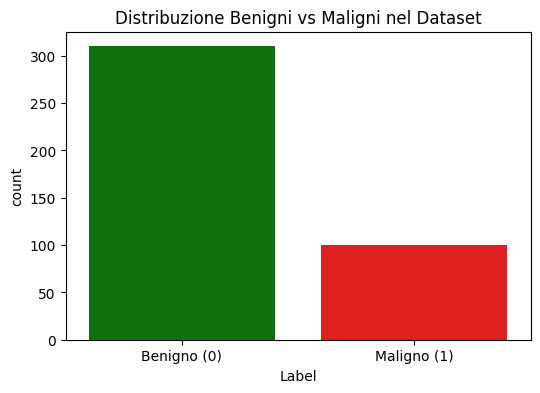

In [ ]:
# --- STEP 6: CONVERSIONE IN CLASSI BINARIE ---

def mappa_birads(valore):
    # Convertiamo in intero (gestisce anche stringhe tipo '4a', '4b' se ce ne fossero)
    try:
        v = int(str(valore)[0]) # Prende solo la prima cifra (es '4a' -> 4)
    except:
        return None # Gestione errori

    if v in [1, 2, 3]:
        return 0 # Classe BENIGNO
    elif v in [4, 5, 6]:
        return 1 # Classe MALIGNO
    else:
        return None # BI-RADS 0 o errori

# Applichiamo la funzione
df_final['Label'] = df_final['Bi-Rads'].apply(mappa_birads)

# Rimuoviamo eventuali righe che non siamo riusciti a classificare
df_final = df_final.dropna(subset=['Label'])
df_final['Label'] = df_final['Label'].astype(int)

# Visualizziamo la distribuzione
print("✅ Conversione completata!")
print("Distribuzione Classi:")
print(df_final['Label'].value_counts())

# Grafico per vedere se è bilanciato
plt.figure(figsize=(6, 4))
sns.countplot(x='Label', data=df_final, palette=['green', 'red'])
plt.xticks([0, 1], ['Benigno (0)', 'Maligno (1)'])
plt.title('Distribuzione Benigni vs Maligni nel Dataset')
plt.show()

In [ ]:
print("🔍 Cerco un file .roi di esempio...")

roi_files_found = []
# Cerca ricorsivamente nella cartella estratta
for root, dirs, files in os.walk('/content/data/INbreast_extracted'):
    for file in files:
        if file.endswith('.roi'):
            roi_files_found.append(os.path.join(root, file))

if roi_files_found:
    sample_roi = roi_files_found[0]
    print(f"📄 Trovato: {sample_roi}")
    print("-" * 30)
    print("CONTENUTO DEL FILE (Primi 500 caratteri):")
    print("-" * 30)

    try:
        # Proviamo a leggerlo come testo
        with open(sample_roi, 'r', encoding='utf-8', errors='replace') as f:
            content = f.read(500)
            print(content)
    except Exception as e:
        print(f"❌ Impossibile leggere il file come testo: {e}")

    print("-" * 30)
else:
    print("⚠️ Nessun file .roi trovato nelle cartelle estratte!")

🔍 Cerco un file .roi di esempio...
📄 Trovato: /content/data/INbreast_extracted/INbreast/INbreast Release 1.0/PectoralMuscle/Pectoral Muscle ROI/50998440_muscle.roi
------------------------------
CONTENUTO DEL FILE (Primi 500 caratteri):
------------------------------
streamtyped���@���NSMutableArray ��NSArray ��NSObject ��i����ROI���������MyPoint �����NSString��+{2759.05, 6.62378}���������{2779.96, 53.4911}���������{2798.42, 117.778}���������{2810, 177.986}���������{2821.57, 247.457}���������{2835.47, 312.297}���������{2847.05, 384.084}���������{2860.94, 460.502}���������{2874.84, 529.974}���������{2891.05, 617.971}���������{2904.94, 689.758}���������{2921.15, 761.545}���������{2946.62, 861.12}���������{2976.73, 942.17}���������
------------------------------


In [ ]:
import re
import numpy as np
import cv2 # OpenCV per il ridimensionamento
from google.colab.patches import cv2_imshow # Per vedere le immagini su Colab

# --- FUNZIONE 1: PARSER DEL FILE .ROI (Il "Decodificatore") ---
def parse_roi_file(roi_path):
    """
    Legge un file .roi di INbreast e restituisce una lista di coordinate (x, y).
    Usa Regex per trovare i pattern {numero, numero}.
    """
    try:
        with open(roi_path, 'r', encoding='utf-8', errors='ignore') as f:
            content = f.read()

        # Questa regex cerca pattern tipo {1234.56, 789.10}
        # Spiegazione regex: \{ = parentesi graffa aperta, ([0-9.]+) = cattura numero
        points_str = re.findall(r'\{([0-9.]+),\s*([0-9.]+)\}', content)

        points = []
        for p in points_str:
            x, y = float(p[0]), float(p[1])
            points.append([x, y])

        return np.array(points)
    except Exception as e:
        print(f"Errore lettura ROI {roi_path}: {e}")
        return None

# --- FUNZIONE 2: PRENDI IL QUADRATO (Bounding Box) ---
def get_bounding_box(points, img_shape):
    """
    Dai punti del contorno, calcola il rettangolo (min_x, min_y, max_x, max_y).
    Aggiunge un piccolo margine (padding) per non tagliare il bordo del tumore.
    """
    if points is None or len(points) == 0:
        return None

    # Coordinate minime e massime
    min_x = np.min(points[:, 0])
    max_x = np.max(points[:, 0])
    min_y = np.min(points[:, 1])
    max_y = np.max(points[:, 1])

    # Aggiungiamo un margine del 10% (Padding)
    width = max_x - min_x
    height = max_y - min_y
    margin = int(max(width, height) * 0.1)

    # Coordinate finali (facendo attenzione a non uscire dall'immagine)
    x1 = int(max(0, min_x - margin))
    y1 = int(max(0, min_y - margin))
    x2 = int(min(img_shape[1], max_x + margin))
    y2 = int(min(img_shape[0], max_y + margin))

    return (x1, y1, x2, y2)

def process_single_case(dicom_path, roi_path_list):
    """
    Versione FINAL: Scarta muscoli, scarta ROI giganti E scarta ROI nere (vuote).
    """
    ds = pydicom.dcmread(dicom_path)
    img = ds.pixel_array
    total_area = img.shape[0] * img.shape[1]

    # Normalizza a 0-255
    img_norm = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    best_crop = None
    best_roi_name = None
    max_brightness_found = 0 # Cerchiamo la ROI più "bianca" (più densa/significativa)

    for r_path in roi_path_list:
        # Filtro 1: Niente muscoli
        if "muscle" in r_path.lower() or "pectoral" in r_path.lower():
            continue

        points = parse_roi_file(r_path)
        if points is not None and len(points) > 3:
            bbox = get_bounding_box(points, img.shape)
            if bbox is None: continue

            x1, y1, x2, y2 = bbox
            crop_area = (x2 - x1) * (y2 - y1)

            # Filtro 2: LA REGOLA DEL 40% (Niente contorni giganti)
            coverage = crop_area / total_area
            if coverage > 0.40:
                continue

            # --- FILTRO 3 (NUOVO!): CONTROLLO LUMINOSITÀ ---
            # Estraiamo il crop provvisorio
            temp_crop = img_norm[y1:y2, x1:x2]
            if temp_crop.size == 0: continue

            avg_brightness = np.mean(temp_crop)

            # Se l'immagine è troppo scura (quasi tutta nera), è spazzatura.
            # Una lesione vera è densa (chiara). Soglia empirica: 30 su 255.
            if avg_brightness < 30:
                continue

            # Se arriviamo qui, è una ROI valida.
            # Strategia: Prendiamo quella con la luminosità media più alta (il tumore è bianco!)
            # invece che la più piccola. Questo aiuta a centrare la massa.
            if avg_brightness > max_brightness_found:
                max_brightness_found = avg_brightness
                best_crop = temp_crop
                best_roi_name = r_path

    if best_crop is None:
        return None, None

    # Resize finale per Swin Transformer
    img_final = cv2.resize(best_crop, (224, 224), interpolation=cv2.INTER_CUBIC)

    return img_final, best_roi_name

In [ ]:
# --- TEST VISIVO ---
print("🔬 Test del sistema di ritaglio su un caso Maligno...")

# 1. Trova tutti i file ROI nel sistema
all_rois = []
for root, dirs, files in os.walk('/content/data/INbreast_extracted'):
    for file in files:
        if file.endswith('.roi'):
            all_rois.append(os.path.join(root, file))

# 2. Prendi un caso Maligno (Bi-Rads 4, 5, 6 -> Label 1)
malignant_cases = df_final[df_final['Label'] == 1]

if not malignant_cases.empty:
    # Ne prendiamo uno a caso
    sample = malignant_cases.iloc[0]
    pid = sample['PatientID']
    dcm_path = sample['file_path']

    print(f"Paziente Test: {pid}")

    # 3. Cerca i file ROI che appartengono a questo paziente
    # (Il nome del file ROI di solito contiene l'ID del paziente)
    patient_rois = [r for r in all_rois if str(pid) in r]

    if patient_rois:
        print(f"Trovati {len(patient_rois)} file ROI candidati.")

        # 4. PROVA IL RITAGLIO
        cropped_img, roi_used = process_single_case(dcm_path, patient_rois)

        if cropped_img is not None:
            print(f"✅ Successo! ROI usata: {os.path.basename(roi_used)}")

            plt.figure(figsize=(10, 5))

            # Mostra originale (ridimensionata per display)
            ds = pydicom.dcmread(dcm_path)
            plt.subplot(1, 2, 1)
            plt.imshow(ds.pixel_array, cmap='gray')
            plt.title("Mammografia Intera (4000px)")
            plt.axis('off')

            # Mostra il ritaglio
            plt.subplot(1, 2, 2)
            plt.imshow(cropped_img, cmap='gray')
            plt.title("Ritaglio Lesione (224x224)\nInput per Swin Transformer")
            plt.axis('off')

            plt.show()
        else:
            print("❌ Trovati file ROI ma nessuno era una lesione valida (forse solo muscoli?).")
    else:
        print("⚠️ Nessun file ROI trovato per questo paziente maligno.")
else:
    print("Nessun caso maligno nel dataframe?!")

🔬 Test del sistema di ritaglio su un caso Maligno...
Paziente Test: 22580038
Trovati 1 file ROI candidati.
❌ Trovati file ROI ma nessuno era una lesione valida (forse solo muscoli?).


🔬 Cerco un caso Maligno con una ROI valida (tumore vero)...

✅ TROVATO! Paziente: 50994354
📄 ROI usata: 50994354.roi


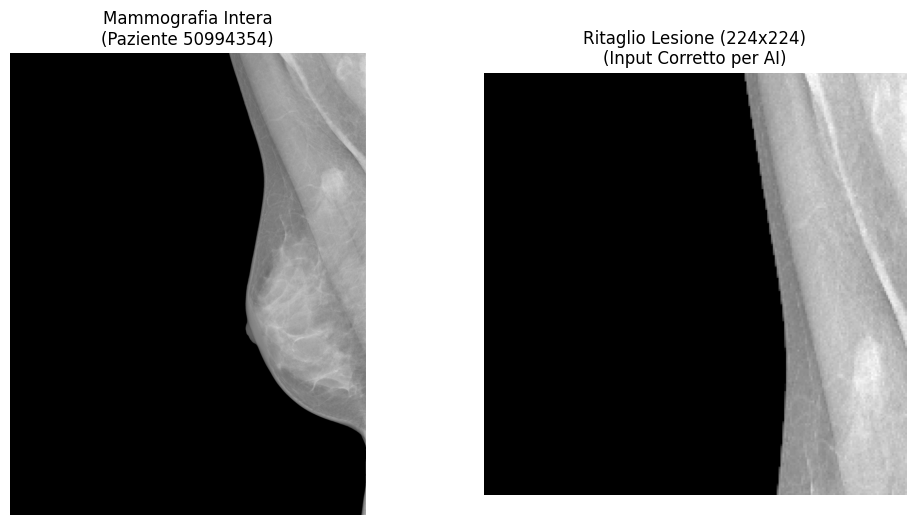

In [ ]:
# --- TEST VISIVO AVANZATO (Cerca un caso valido) ---
print("🔬 Cerco un caso Maligno con una ROI valida (tumore vero)...")

# 1. Trova tutti i file ROI nel sistema
all_rois = []
for root, dirs, files in os.walk('/content/data/INbreast_extracted'):
    for file in files:
        if file.endswith('.roi'):
            all_rois.append(os.path.join(root, file))

# 2. Prendi tutti i casi Maligni
malignant_cases = df_final[df_final['Label'] == 1]

found_valid_case = False

# 3. Ciclo sui primi 50 pazienti maligni finché non ne trovo uno buono
for index, sample in malignant_cases.head(50).iterrows():
    pid = sample['PatientID']
    dcm_path = sample['file_path']

    # Cerca ROI per questo paziente
    patient_rois = [r for r in all_rois if str(pid) in r]

    if not patient_rois:
        continue # Nessuna ROI per questo, avanti il prossimo

    # Prova a processarlo con la logica "Smart"
    cropped_img, roi_used = process_single_case(dcm_path, patient_rois)

    if cropped_img is not None:
        print(f"\n✅ TROVATO! Paziente: {pid}")
        print(f"📄 ROI usata: {os.path.basename(roi_used)}")

        plt.figure(figsize=(12, 6))

        # Originale
        ds = pydicom.dcmread(dcm_path)
        plt.subplot(1, 2, 1)
        plt.imshow(ds.pixel_array, cmap='gray')
        plt.title(f"Mammografia Intera\n(Paziente {pid})")
        plt.axis('off')

        # Ritaglio
        plt.subplot(1, 2, 2)
        plt.imshow(cropped_img, cmap='gray')
        plt.title("Ritaglio Lesione (224x224)\n(Input Corretto per AI)")
        plt.axis('off')

        plt.show()

        found_valid_case = True
        break # Fermati al primo successo!

if not found_valid_case:
    print("\n⚠️ Ho controllato 50 pazienti maligni ma nessuno aveva una ROI 'piccola' valida.")
    print("Potrebbe essere necessario alzare la soglia del 40% o controllare i file ROI.")

## Caricamento BreastMNIST e Exploratory Data Analysis

Jiancheng Yang, Rui Shi, Donglai Wei, Zequan Liu, Lin Zhao, Bilian Ke, Hanspeter Pfister, Bingbing Ni. Yang, Jiancheng, et al. "MedMNIST v2-A large-scale lightweight benchmark for 2D and 3D biomedical image classification." Scientific Data, 2023.
                            
  Jiancheng Yang, Rui Shi, Bingbing Ni. "MedMNIST Classification Decathlon: A Lightweight AutoML Benchmark for Medical Image Analysis". IEEE 18th International Symposium on Biomedical Imaging (ISBI), 2021.

In [1]:
!pip install medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 3.1 MB/s eta 0:00:00


In [3]:
import medmnist
from medmnist import BreastMNIST, INFO

In [4]:
print(f"MedMNIST v{medmnist.__version__} installato correttamente.")
# Statistiche del dataset (recuperate dai metadati ufficiali)
data_flag = 'breastmnist'
info = INFO[data_flag]
n_channels = info['n_channels']
n_classes = len(info['label'])
class_names = info['label'] # es. {0: 'malignant', 1: 'normal, benign'}
print(class_names)

MedMNIST v3.0.2 installato correttamente.
{'0': 'malignant', '1': 'normal, benign'}


In [1]:
data_transform = transforms.ToTensor()

train_dataset = BreastMNIST(split='train', transform=data_transform, download=True)
val_dataset = BreastMNIST(split='val', transform=data_transform, download=True)
test_dataset = BreastMNIST(split='test', transform=data_transform, download=True)

print("\n--- 1. STRUTTURA DEL DATASET ---")
print(f"Dimensioni Immagine (C, H, W): {train_dataset[0][0].shape}")
print(f"Tipo di dato: {train_dataset[0][0].dtype}")
print(f"Mapping Classi: {label_dict}")
print(f"Numero campioni Training: {len(train_dataset)}")
print(f"Numero campioni Validation: {len(val_dataset)}")
print(f"Numero campioni Test: {len(test_dataset)}")

NameError: name 'transforms' is not defined

In [ ]:
output_dir = '/content/eda_results'
os.makedirs(output_dir, exist_ok=True)

# Impostazioni grafiche per qualità "Pubblicazione"
plt.rcParams['figure.dpi'] = 300       # Alta risoluzione a schermo
plt.rcParams['savefig.dpi'] = 300      # Alta risoluzione salvataggio
plt.rcParams['font.size'] = 12         # Testo leggibile
plt.rcParams['font.family'] = 'serif'  # Font stile LaTeX (opzionale)
sns.set_style("whitegrid")             # Sfondo pulito con griglia leggera

print(f"📂 I grafici verranno salvati in: {output_dir}")

In [ ]:
# Uniamo le etichette di tutti i set per vedere la distribuzione globale
all_labels = np.concatenate([
    train_dataset.labels,
    val_dataset.labels,
    test_dataset.labels
])

# Creiamo un DataFrame per Seaborn
df_labels = pd.DataFrame(all_labels, columns=['label'])
df_labels['Diagnosis'] = df_labels['label'].map(class_map)

plt.figure(figsize=(8, 6))
# Countplot con colori distinti
ax = sns.countplot(x='Diagnosis', data=df_labels, palette=['#d62728', '#2ca02c']) # Rosso=Maligno, Verde=Benigno

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), textcoords='offset points', fontsize=12, fontweight='bold')

plt.title('Class Distribution in BreastMNIST (Total)', fontsize=14, fontweight='bold')
plt.xlabel('Diagnosis', fontsize=12)
plt.ylabel('Number of Samples', fontsize=12)

# SALVATAGGIO
plt.savefig(f"{output_dir}/01_class_distribution.pdf", bbox_inches='tight') # Vettoriale per LaTeX
plt.savefig(f"{output_dir}/01_class_distribution.png", bbox_inches='tight') # Raster per Slide
plt.show()

In [ ]:
def get_indices(dataset, class_id, num=5):
    return np.where(dataset.labels == class_id)[0][:num]

idx_malignant = get_indices(train_dataset, 0, 5)
idx_benign = get_indices(train_dataset, 1, 5)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# Riga 1: Maligni
for i, idx in enumerate(idx_malignant):
    img = train_dataset.imgs[idx]
    axes[0, i].imshow(img, cmap='gray')
    axes[0, i].set_title(f"Malignant\n(ID: {idx})", color='#d62728', fontweight='bold')
    axes[0, i].axis('off')

# Riga 2: Benigni
for i, idx in enumerate(idx_benign):
    img = train_dataset.imgs[idx]
    axes[1, i].imshow(img, cmap='gray')
    axes[1, i].set_title(f"Benign\n(ID: {idx})", color='#2ca02c', fontweight='bold')
    axes[1, i].axis('off')

plt.suptitle(f"Sample Images from BreastMNIST ({28}x{28} pixels)", fontsize=16)
plt.tight_layout()

# SALVATAGGIO
plt.savefig(f"{output_dir}/02_sample_grid.pdf", bbox_inches='tight')
plt.savefig(f"{output_dir}/02_sample_grid.png", bbox_inches='tight')
plt.show()

# --- 4. ANALISI PIXEL (MEDIA E DEVIAZIONE) ---
print("📈 Generazione Istogramma Pixel...")

# Normalizziamo a 0-1 per il grafico
pixel_values = train_dataset.imgs.flatten() / 255.0

plt.figure(figsize=(10, 6))
sns.histplot(pixel_values, bins=50, kde=True, color='purple', stat='density', alpha=0.6)
plt.title('Pixel Intensity Distribution (Training Set)', fontsize=14, fontweight='bold')
plt.xlabel('Pixel Value (0=Black, 1=White)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.xlim(0, 1)

# Aggiungiamo linee per media e deviazione
mean_val = np.mean(pixel_values)
plt.axvline(mean_val, color='k', linestyle='dashed', linewidth=1, label=f'Mean: {mean_val:.2f}')
plt.legend()

# SALVATAGGIO
plt.savefig(f"{output_dir}/03_pixel_distribution.pdf", bbox_inches='tight')
plt.savefig(f"{output_dir}/03_pixel_distribution.png", bbox_inches='tight')
plt.show()

In [ ]:
print("🧠 Generazione Immagine Media...")
# Calcoliamo l'immagine media per classe per vedere se ci sono pattern spaziali (es. tumore sempre al centro)

imgs = train_dataset.imgs
labels = train_dataset.labels.squeeze()

mean_mal = np.mean(imgs[labels == 0], axis=0)
mean_ben = np.mean(imgs[labels == 1], axis=0)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

im0 = ax[0].imshow(mean_mal, cmap='magma')
ax[0].set_title('Average Malignant Image')
ax[0].axis('off')
plt.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.04)

im1 = ax[1].imshow(mean_ben, cmap='magma')
ax[1].set_title('Average Benign Image')
ax[1].axis('off')
plt.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.04)

# Differenza
diff = mean_mal - mean_ben
im2 = ax[2].imshow(diff, cmap='coolwarm')
ax[2].set_title('Difference (Malignant - Benign)')
ax[2].axis('off')
plt.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.04)

plt.suptitle("Spatial Analysis: Average Patterns", fontsize=16)
plt.tight_layout()

# SALVATAGGIO
plt.savefig(f"{output_dir}/04_average_patterns.pdf", bbox_inches='tight')
plt.savefig(f"{output_dir}/04_average_patterns.png", bbox_inches='tight')
plt.show()

## Swin B Transformer classico

In [ ]:
weights = Swin_B_Weights.IMAGENET1K_V1
model = swin_b(weights=weights)

In [ ]:
for param in model.parameters():
    param.requires_grad = True

num_features = model.head.in_features

In [ ]:
model.head = nn.Sequential(
    nn.Linear(num_features, 1024),
    nn.ReLU(),
    nn.Linear(1024, 16),
    nn.Linear(16, 2)
)